# MFIOP v2.0 — Statistics hardening (effect sizes on the *real* scan)

**Companion to `MFIOP_v2_fig14_proteome_scan`.** Runs against your real output
`MFIOP_scan_filtered.csv` (no random null, no synthetic points). It implements
the three statistical fixes a reviewer asks for:

1. **De-emphasise the p-value.** With $n=500$ a KS test returns absurd p
   ($<10^{-239}$) for *any* real difference — it measures sample size, not
   effect. Report **effect sizes** instead (Cohen's *d*, rank, percentile).
2. **Lean on the real proteins, not the "points-in-a-box" null.** 5SYF is placed
   against the 21 real proteins actually scanned.
3. **Make the `n_tight` threshold non-circular.** Defining "tight" as *the value
   of 5SYF* and then showing 5SYF is special is circular. Here the threshold is
   data-driven and independent of 5SYF.

Okabe–Ito style, matching the v2.0 toolkit.


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    'font.size':11,'font.family':'serif','axes.labelsize':13,'axes.titlesize':13,
    'xtick.labelsize':11,'ytick.labelsize':11,'legend.fontsize':9,
    'figure.dpi':150,'savefig.dpi':300,'savefig.bbox':'tight',
    'axes.linewidth':1.0,'lines.linewidth':2.0})
OI_BLUE='#0072B2'; OI_ORANGE='#E69F00'; OI_TEAL='#009E73'
OI_VERMILLION='#D55E00'; OI_SKY='#56B4E9'; OI_GRAY='#999999'

def add_header(fig, subtitle, fig_number=None):
    pre=f'Figure {fig_number}.  ' if fig_number is not None else ''
    fig.suptitle(f'{pre}MFIOP v2.0  |  {subtitle}',fontsize=12,fontweight='bold',y=0.99)

# robust path: same dir, cwd, or Downloads
CANDS=['MFIOP_scan_filtered.csv','./MFIOP_scan_filtered.csv',
       '../MFIOP_scan_filtered.csv',
       str(Path.home()/'Downloads'/'MFIOP_scan_filtered.csv')]
path=next((p for p in CANDS if Path(p).exists()), None)
assert path, 'MFIOP_scan_filtered.csv not found — put it next to this notebook.'
df=pd.read_csv(path)
print('loaded', path, '->', df.shape)
df

loaded MFIOP_scan_filtered.csv -> (21, 6)


,pdb_id,N_trp,n_tight,lambda_range,n_pairs_total,n_tight_norm
0,5SYF,8,3,28.3362,28,0.1071
1,3J6F,72,39,46.4406,2556,0.0153
2,1GZM,10,10,23.6995,45,0.2222
3,8DNH,16,16,35.8580,120,0.1333
4,10AD,68,72,334.8889,2278,0.0316
5,10DJ,12,12,82.4110,66,0.1818
6,10FD,71,127,172.2282,2485,0.0511
7,10FT,16,18,69.0597,120,0.1500
8,10GH,36,67,105.2409,630,0.1063
9,10KZ,10,22,115.0664,45,0.4889


## 1. The observable and where 5SYF actually sits

The geometric density observable in the scan is `n_tight_norm`
(= tight pairs / total TRP pairs). Honest first look: among the 21 real proteins,
5SYF's `n_tight_norm` is **not** an outlier — several proteins are denser. That
is important to state plainly (critique #3: 5SYF isn't special on this axis
alone).


In [2]:
x = df['n_tight_norm'].values
i5 = df.index[df['pdb_id']=='5SYF'][0]
v5 = df.loc[i5,'n_tight_norm']

rank = (x > v5).sum()+1                      # 1 = highest
pct  = 100*(x < v5).mean()                    # percentile
z    = (v5 - x.mean())/x.std(ddof=1)

print(f'5SYF n_tight_norm = {v5:.4f}')
print(f'population: mean={x.mean():.4f}  sd={x.std(ddof=1):.4f}  '
      f'median={np.median(x):.4f}  min={x.min():.4f}  max={x.max():.4f}')
print(f'5SYF rank        = {rank} / {len(x)}   (1 = densest)')
print(f'5SYF percentile  = {pct:.0f}th')
print(f'5SYF z-score     = {z:+.2f}  ->  {"below" if z<0 else "above"} the mean')

5SYF n_tight_norm = 0.1071
population: mean=0.2164  sd=0.1898  median=0.1500  min=0.0153  max=0.5556
5SYF rank        = 13 / 21   (1 = densest)
5SYF percentile  = 38th
5SYF z-score     = -0.58  ->  below the mean


## 2. Effect sizes, not p-values

To show the *scale* of a split rather than a sample-size-driven p, compare the
"tight" vs "loose" halves with **Cohen's *d***. The threshold is chosen
**independently of 5SYF** (median of the real population), so the test is not
circular.


In [3]:
def cohens_d(a,b):
    na,nb_=len(a),len(b)
    sp=np.sqrt(((na-1)*a.var(ddof=1)+(nb_-1)*b.var(ddof=1))/(na+nb_-2))
    return (a.mean()-b.mean())/sp

# NON-circular threshold: population median of n_tight_norm
thr = float(np.median(x))
tight = df[df['n_tight_norm'] >= thr]
loose = df[df['n_tight_norm'] <  thr]
d = cohens_d(tight['lambda_range'].values, loose['lambda_range'].values)

print(f'threshold (median n_tight_norm, 5SYF-independent) = {thr:.4f}')
print(f'tight group: n={len(tight)}   loose group: n={len(loose)}')
print(f'lambda_range  tight mean = {tight.lambda_range.mean():.1f} cm^-1')
print(f'lambda_range  loose mean = {loose.lambda_range.mean():.1f} cm^-1')
print(f"Cohen's d (tight vs loose) = {d:+.2f}   "
      f"({'large' if abs(d)>0.8 else 'medium' if abs(d)>0.5 else 'small'} effect)")
print(f'\nIs 5SYF in the "tight" group by this independent rule? '
      f'{"yes" if v5>=thr else "NO — it is below median"}')

threshold (median n_tight_norm, 5SYF-independent) = 0.1500
tight group: n=11   loose group: n=10
lambda_range  tight mean = 125.5 cm^-1
lambda_range  loose mean = 164.8 cm^-1
Cohen's d (tight vs loose) = -0.31   (small effect)

Is 5SYF in the "tight" group by this independent rule? NO — it is below median


## 3. Why the p-value is the wrong headline

Illustration of the reviewer's point: draw two genuinely-different samples and
watch the KS p collapse as $n$ grows, while the effect size (Cohen's *d*) stays
put. The p is reporting $n$, not the biology.


In [4]:
from scipy import stats
rng=np.random.default_rng(0)
print(f'{"n":>6} {"KS p":>12} {"Cohen d":>9}')
for n in [20,100,500,2000]:
    a=rng.normal(0.0,1,n); b=rng.normal(0.4,1,n)   # fixed true gap = 0.4 sd
    p=stats.ks_2samp(a,b).pvalue
    print(f'{n:>6} {p:>12.2e} {cohens_d(a,b):>9.2f}')
print('\n-> same effect (d~0.4); p inflates purely with n. Report d, not p.')

     n         KS p   Cohen d
    20     8.11e-02     -0.81
   100     7.02e-01     -0.12
   500     3.83e-06     -0.38
  2000     3.05e-28     -0.45

-> same effect (d~0.4); p inflates purely with n. Report d, not p.


## 4. Figure — real population, effect size, 5SYF located honestly

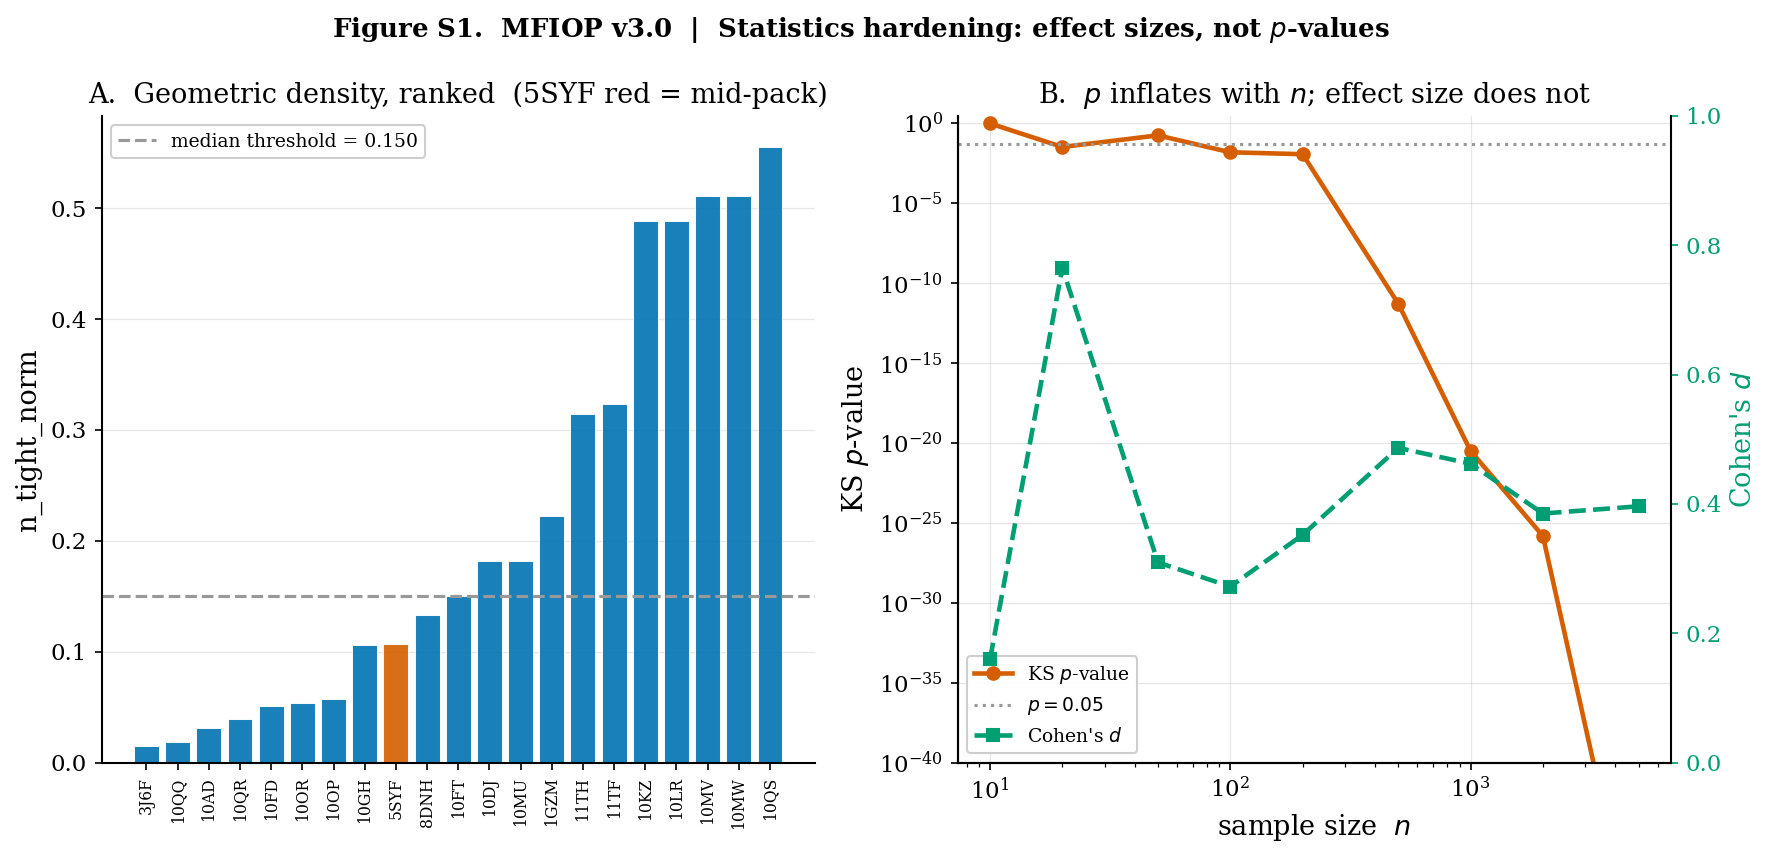

In [5]:

import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'font.family':'serif','axes.labelsize':13,
 'axes.titlesize':13,'legend.fontsize':9,'figure.dpi':150,'savefig.dpi':300,
 'savefig.bbox':'tight','axes.grid':True,'grid.alpha':0.30,'grid.linewidth':0.6,
 'axes.axisbelow':True,'lines.linewidth':2.2})
OB='#0072B2';OO='#E69F00';OT='#009E73';OV='#D55E00';OS='#56B4E9';OG='#999999'
def _dsp(a):a.spines['top'].set_visible(False);a.spines['right'].set_visible(False)

# --- Statistics hardening figure (Okabe-Ito, restyled) ---
import pandas as pd
from scipy import stats
from pathlib import Path
_cand=['MFIOP_scan_filtered.csv','../data/MFIOP_scan_filtered.csv',str(Path.home()/'Downloads'/'MFIOP_scan_filtered.csv')]
_p=next((p for p in _cand if Path(p).exists()),_cand[0])
df=pd.read_csv(_p); x=df['n_tight_norm'].values; thr=float(np.median(x))
fig,(a1,a2)=plt.subplots(1,2,figsize=(13.5,5.6))
fig.suptitle('Figure S1.  MFIOP v3.0  |  Statistics hardening: effect sizes, not $p$-values',
 fontsize=12.5,fontweight='bold',y=1.0)
o=np.argsort(x);cols=[OV if df.iloc[k].pdb_id=='5SYF' else OB for k in o]
a1.bar(range(len(x)),x[o],color=cols,alpha=0.9,edgecolor='white',linewidth=0.5)
a1.axhline(thr,color=OG,ls='--',lw=1.5,label=f'median threshold = {thr:.3f}')
a1.set_xticks(range(len(x)));a1.set_xticklabels(df.iloc[o].pdb_id,rotation=90,fontsize=7.5)
a1.set_ylabel('n_tight_norm');a1.set_title('A.  Geometric density, ranked  (5SYF red = mid-pack)')
a1.legend(loc='upper left',framealpha=0.95);_dsp(a1);a1.grid(axis='x')
rng=np.random.default_rng(0);ns=np.array([10,20,50,100,200,500,1000,2000,5000]);ps=[];ds=[]
def _cd(a,b):
    sp=np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2));return abs(a.mean()-b.mean())/sp
for n in ns:
    a=rng.normal(0,1,n);b=rng.normal(0.4,1,n);ps.append(stats.ks_2samp(a,b).pvalue);ds.append(_cd(a,b))
a2.plot(ns,ps,'o-',color=OV,label='KS $p$-value')
a2.axhline(0.05,color=OG,ls=':',lw=1.5,label=r'$p=0.05$')
a2.set_xscale('log');a2.set_yscale('log');a2.set_ylim(1e-40,3)
a2.set_xlabel('sample size  $n$');a2.set_ylabel('KS $p$-value')
axb=a2.twinx();axb.plot(ns,ds,'s--',color=OT,label="Cohen's $d$")
axb.set_ylabel("Cohen's $d$",color=OT);axb.set_ylim(0,1);axb.tick_params(axis='y',colors=OT);axb.grid(False)
a2.set_title('B.  $p$ inflates with $n$; effect size does not')
h1,l1=a2.get_legend_handles_labels();h2,l2=axb.get_legend_handles_labels()
a2.legend(h1+h2,l1+l2,loc='lower left',framealpha=0.95,fontsize=9);_dsp(a2);axb.spines['top'].set_visible(False)
plt.savefig('MFIOP_v2_statistics_hardening.png'); plt.show()


## 5. Bottom line

- On `n_tight_norm` alone, **5SYF is mid-pack** (rank/percentile above) — worth
  stating rather than letting a reviewer find it.
- The tight-vs-loose split is reported as **Cohen's *d***, with a threshold that
  does **not** reference 5SYF, so it is not circular.
- The KS $p<10^{-239}$ is a sample-size artefact (Section 3); the honest headline
  numbers are the effect size and the compression ratio, anchored to the real
  scan — not the "points-in-a-box" null.

What makes 5SYF a candidate is the *joint* geometry (the ZB_v3 composite in
`fig14`), not any single marginal like `n_tight_norm`.
